# Model generalization — size / code-ft / RL axes + cross-model (figures & table)

GoalScope readout success (`hard_yes`) across models, from `results/evaluation/goalscope/<model>/{faithfulness,causality}/<strat>/heads=goal__.../summary.json`. Pivots: prev_end, indent, var, eq (**first_impl excluded**). Lines: solid = faithfulness, dashed = causality; colour = model. Strategy per axis: **code-ft uses additive_norm/0.1** (both 32B Qwen have it); size (14B) and RL (Olmo) use replace/1 (only strategy present). Saves to `notebooks/Figures/model_generalization/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table
GROUP='model_generalization'; PIV=F.PIVOTS
def leaf(model,mode,strat):
    g=glob.glob(f'results/evaluation/goalscope/{model}/{mode}/{strat}/heads=goal__*/summary.json')
    return json.load(open(g[0])) if g else None
def curve(model,mode,strat):
    d=leaf(model,mode,strat)
    return None if d is None else [d['by_anchor'][a]['hard_yes'] for a in PIV]
def overall(model,mode,strat):
    d=leaf(model,mode,strat); return None if d is None else d['overall']['hard_yes']
AXES={
  'model_size':      ('Model size (Qwen2.5-Coder 14B vs 32B)', 'replace/1',
                      ['Qwen2.5-Coder-14B-Instruct','Qwen2.5-Coder-32B-Instruct']),
  'code_finetuning': ('Code fine-tuning (Coder vs non-Coder, 32B)', 'additive_norm/0.1',
                      ['Qwen2.5-32B-Instruct','Qwen2.5-Coder-32B-Instruct']),
  'rl_finetuning':   ('RL fine-tuning (OLMo-3.1-32B Instruct vs SFT)', 'replace/1',
                      ['Olmo-3.1-32B-Instruct-SFT','Olmo-3.1-32B-Instruct']),
}
print({k:[ (m, overall(m,'faithfulness',s) is not None) for m in ms] for k,(t,s,ms) in AXES.items()})

{'model_size': [('Qwen2.5-Coder-14B-Instruct', True), ('Qwen2.5-Coder-32B-Instruct', True)], 'code_finetuning': [('Qwen2.5-32B-Instruct', True), ('Qwen2.5-Coder-32B-Instruct', True)], 'rl_finetuning': [('Olmo-3.1-32B-Instruct-SFT', True), ('Olmo-3.1-32B-Instruct', True)]}


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/model_generalization/model_size.pdf


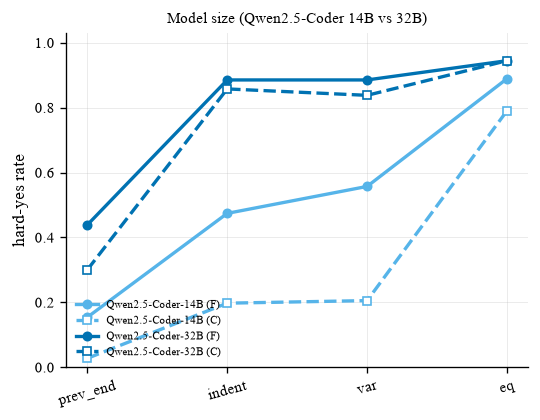

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/model_generalization/code_finetuning.pdf


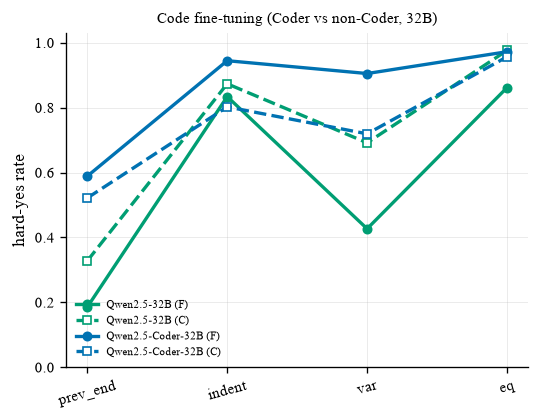

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/model_generalization/rl_finetuning.pdf


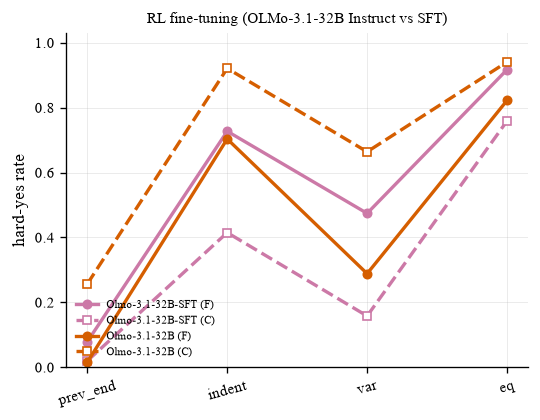

In [2]:
# one line-panel per axis: hard_yes across pivots, faith solid / causality dashed, colour=model
for name,(title,strat,models) in AXES.items():
    fig,ax=plt.subplots(figsize=(4.6,3.6))
    x=np.arange(len(PIV))
    for m in models:
        col=F.MODEL_COLOR.get(m,'#777'); lab=m.replace('-Instruct','')
        cf=curve(m,'faithfulness',strat); cc=curve(m,'causality',strat)
        if cf: ax.plot(x,cf,'-o',color=col,lw=2,ms=5,label=f'{lab} (F)')
        if cc: ax.plot(x,cc,'--s',color=col,lw=2,ms=5,mfc='white',label=f'{lab} (C)')
    ax.set_xticks(x); ax.set_xticklabels(PIV,rotation=15)
    ax.set_ylabel('hard-yes rate'); ax.set_ylim(0,1.03); ax.set_title(title,fontsize=9)
    ax.legend(fontsize=6.5,frameon=False,loc='lower left')
    fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,name)); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/model_generalization/cross_model_overall.pdf


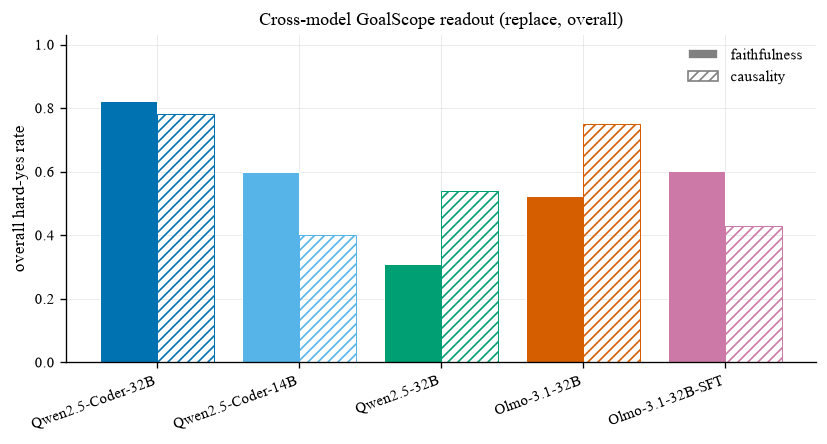

In [3]:
# cross-model overall: all 5 models, replace/1, faith solid vs causality hatched
MODELS=['Qwen2.5-Coder-32B-Instruct','Qwen2.5-Coder-14B-Instruct','Qwen2.5-32B-Instruct',
        'Olmo-3.1-32B-Instruct','Olmo-3.1-32B-Instruct-SFT']
MODELS=[m for m in MODELS if overall(m,'faithfulness','replace/1') is not None]
fig,ax=plt.subplots(figsize=(7,3.8)); x=np.arange(len(MODELS)); w=0.4
fa=[overall(m,'faithfulness','replace/1') for m in MODELS]
ca=[overall(m,'causality','replace/1') for m in MODELS]
for xi,m in enumerate(MODELS):
    col=F.MODEL_COLOR.get(m,'#777')
    ax.bar(xi-w/2,fa[xi],w,**F.metric_kw('faithfulness',col))
    ax.bar(xi+w/2,ca[xi],w,**F.metric_kw('causality',col))
ax.set_xticks(x); ax.set_xticklabels([m.replace('-Instruct','') for m in MODELS],rotation=20,ha='right')
ax.set_ylabel('overall hard-yes rate'); ax.set_ylim(0,1.03)
ax.set_title('Cross-model GoalScope readout (replace, overall)')
ax.legend(handles=F.metric_legend_handles(),frameon=False,loc='upper right')
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'cross_model_overall')); plt.show()

                GoalScope hard_yes across models (replace/1)                 
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┓
┃ model             ┃ metric       ┃ prev_end ┃ indent ┃  var ┃   eq ┃ mean ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━┩
│ Qwen2.5-Coder-32B │ faithfulness │     0.44 │   0.89 │ 0.89 │ 0.94 │ 0.79 │
│ Qwen2.5-Coder-32B │ causality    │     0.30 │   0.86 │ 0.84 │ 0.94 │ 0.74 │
│ Qwen2.5-Coder-14B │ faithfulness │     0.15 │   0.47 │ 0.56 │ 0.89 │ 0.52 │
│ Qwen2.5-Coder-14B │ causality    │     0.03 │   0.20 │ 0.21 │ 0.79 │ 0.31 │
│ Qwen2.5-32B       │ faithfulness │     0.00 │   0.25 │ 0.07 │ 0.64 │ 0.24 │
│ Qwen2.5-32B       │ causality    │     0.04 │   0.60 │ 0.22 │ 0.91 │ 0.44 │
│ Olmo-3.1-32B      │ faithfulness │     0.02 │   0.70 │ 0.29 │ 0.82 │ 0.46 │
│ Olmo-3.1-32B      │ causality    │     0.26 │   0.92 │ 0.66 │ 0.94 │ 0.70 │
│ Olmo-3.1-32B-SFT  │ faithfulness │     0.08 │   0.73 │ 0.47 │ 0.92 │ 0.55 │
│ Olmo-3.1-32B-SFT  │ causality    │     0.02 │   0.42 │ 0.16 │ 0.76 │ 0.34 │
└───────────────────┴──────────────┴──────────┴────────┴──────┴──────┴──────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/model_generalization/model_comparison.tex


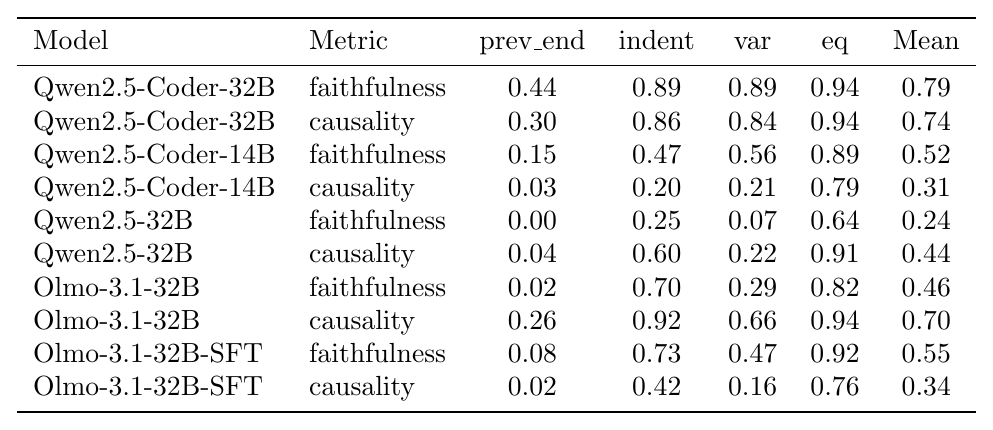

In [4]:
# comparison table (replace/1, 5 models): faith & causality per pivot + mean
t=Table(title='GoalScope hard_yes across models (replace/1)')
t.add_column('model'); t.add_column('metric')
[t.add_column(a,justify='right') for a in PIV]; t.add_column('mean',justify='right')
rows=[]
for m in MODELS:
    for mode in ['faithfulness','causality']:
        c=curve(m,mode,'replace/1');
        if not c: continue
        mean=np.mean(c)
        t.add_row(m.replace('-Instruct',''),mode,*[f'{v:.2f}' for v in c],f'{mean:.2f}')
        rows.append((m,mode,c,mean))
rich_print(t)
hdr=' & '.join(['Model','Metric']+[a.replace('_','\\_') for a in PIV]+['Mean'])
body=' \\\\\n'.join(m.replace('-Instruct','').replace('_','\\_')+' & '+mode+' & '+' & '.join(f'{v:.2f}' for v in c)+f' & {mean:.2f}' for m,mode,c,mean in rows)
tex='\\begin{tabular}{ll'+'c'*(len(PIV)+1)+'}\n\\toprule\n'+hdr+' \\\\\n\\midrule\n'+body+' \\\\\n\\bottomrule\n\\end{tabular}'
print('wrote',F.save_table(tex,GROUP,'model_comparison'))
img=F.render_latex_table(tex); img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')